CELL 1 — IMPORT LIBRARY

In [1]:
import json
import warnings
from datetime import datetime
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from openpyxl import Workbook, load_workbook
from google.colab import files
from scipy.optimize import minimize

warnings.filterwarnings("ignore")

print("✅ Library siap.")

✅ Library siap.


CELL 2 — KONFIGURASI SKENARIO

In [14]:
SKENARIO = {
    "Skenario1": {
        "referensi": {"R1": {"jarak_m": 0.5}, "R2": {"jarak_m": 2.0}},
        "urutan_ref": ["R1", "R2"], # urutan kolom input vektor
    },
    "Skenario2": {
        "referensi": {"R1": {"jarak_m": 0.5}, "R2": {"jarak_m": 1.25}, "R3": {"jarak_m": 2.0}},
        "urutan_ref": ["R1", "R2", "R3"], # urutan kolom input vektor
    },
}

GRID_GAMMA = [0.001, 0.005, 0.01, 0.015, 0.02, 0.05, 0.1]
GRID_C = [1, 10, 50, 100, 200, 500]
GRID_EPSILON = [0.001, 0.005, 0.01, 0.05, 0.1]

print("✅ Konfigurasi skenario:")
for nama, info in SKENARIO.items():
    refs = " | ".join(f"{tag}: {jarak['jarak_m']}m" for tag, jarak in info["referensi"].items())
    print(f"   {nama}: {refs}")

✅ Konfigurasi skenario:
   Skenario1: R1: 0.5m | R2: 2.0m
   Skenario2: R1: 0.5m | R2: 1.25m | R3: 2.0m


CELL 3 — UPLOAD FILE DATA TARGET

In [15]:
"""
Contoh nama file:
    data_Skenario1_LOS_Target_80cm_*.xlsx
    data_Skenario1_LOS_Target_100cm_*.xlsx
    data_Skenario1_LOS_Target_140cm_*.xlsx
    data_Skenario1_LOS_Target_170cm_*.xlsx

Contoh nama file:
    data_Skenario2_LOS_Target_80cm_*.xlsx
    data_Skenario2_LOS_Target_100cm_*.xlsx
    data_Skenario2_LOS_Target_140cm_*.xlsx
    data_Skenario2_LOS_Target_170cm_*.xlsx
"""
print("Upload file data tag target LOS:")
print("Skenario 1: 4 file (80, 100, 140, 170 cm)")
print("Skenario 2: 4 file (80, 100, 140, 170 cm)")
print()

uploaded = files.upload()
target_files = list(uploaded.keys())

print(f"\n✅ File diupload ({len(target_files)} file):")
for fname in target_files:
    print(f"   → {fname}")

Upload file data tag target LOS:
Skenario 1: 4 file (80, 100, 140, 170 cm)
Skenario 2: 4 file (80, 100, 140, 170 cm)



Saving data_Skenario2_LOS_Target_80cm_20260511_123901.xlsx to data_Skenario2_LOS_Target_80cm_20260511_123901.xlsx
Saving data_Skenario2_LOS_Target_100cm_20260511_124629.xlsx to data_Skenario2_LOS_Target_100cm_20260511_124629.xlsx
Saving data_Skenario2_LOS_Target_140cm_20260511_125405.xlsx to data_Skenario2_LOS_Target_140cm_20260511_125405.xlsx
Saving data_Skenario2_LOS_Target_170cm_20260511_130502.xlsx to data_Skenario2_LOS_Target_170cm_20260511_130502.xlsx

✅ File diupload (4 file):
   → data_Skenario2_LOS_Target_80cm_20260511_123901.xlsx
   → data_Skenario2_LOS_Target_100cm_20260511_124629.xlsx
   → data_Skenario2_LOS_Target_140cm_20260511_125405.xlsx
   → data_Skenario2_LOS_Target_170cm_20260511_130502.xlsx


CELL 4 — FUNGSI PREPROCESSING

In [16]:
"""Gaussian Filter — Persamaan 3.1, 3.2, 2.3, 3.3, 3.4."""
def gaussian_filter(rssi_array: np.ndarray, k: float = 1.0, q_threshold: float = 0.5) -> dict:
    n = len(rssi_array)
    k_used = k

    while True:
        xe = np.mean(rssi_array)
        omega = np.sqrt(np.mean((rssi_array - xe) ** 2))
        mask = np.abs(rssi_array - xe) < k_used * omega
        data_bersih = rssi_array[mask]
        P = (len(data_bersih) / n) * 100

        if P >= q_threshold * 100 or k_used >= 3:
            break
        k_used += 1

    xe_bersih = np.mean(data_bersih) if len(data_bersih) > 0 else xe

    return {
        "xe_bersih": xe_bersih,
        "data_bersih": data_bersih,
        "n_buang": n - len(data_bersih),
        "P": P,
        "omega": omega,
    }

"""Kalman Filter — Persamaan 2.4 s/d 2.9. Return xk_final."""
def kalman_filter(rssi_array: np.ndarray, phi: float = 1.0, Q: float = 0.01, Rv: float = 0.1, P0: float = 1.0) -> float:
    x_est, P_est = rssi_array[0], P0

    for zk in rssi_array:
        x_pred = phi * x_est
        P_pred = (phi * P_est * phi) + Q
        Kk = P_pred / (P_pred + Rv)
        x_est = x_pred + Kk * (zk - x_pred)
        P_est = (1 - Kk) * P_pred

    return float(x_est)

"""Pipeline Gaussian → Kalman, return satu nilai xk_final."""
def preprocessing(rssi_array: np.ndarray) -> float:
    hasil_gaussian = gaussian_filter(rssi_array)
    return kalman_filter(hasil_gaussian["data_bersih"])

print("✅ Fungsi preprocessing siap.")

✅ Fungsi preprocessing siap.


CELL 5 — BACA DAN PREPROCESSING DATA TARGET

In [17]:
"""
    Setiap file target berisi sheet: Target, R1, R2 (dan R3 jika skenario 2)
    Input SVR = vektor [xk_R1, xk_R2, xk_Target]
    Output SVR = jarak tag target dalam meter
"""
def baca_data_target(filelist: list, nama_skenario: str) -> list:
    urutan_ref = SKENARIO[nama_skenario]["urutan_ref"]
    hasil = []

    for fname in filelist:
        wb = load_workbook(fname)
        data_per_sheet = {}

        for sheet_name in wb.sheetnames:
            if sheet_name.lower() == "ringkasan":
                continue

            rows = list(wb[sheet_name].iter_rows(values_only=True))
            if len(rows) < 2:
                continue

            df = pd.DataFrame(rows[1:], columns=rows[0])
            df["RSSI (dBm)"] = pd.to_numeric(df["RSSI (dBm)"], errors="coerce")
            df = df.dropna(subset=["RSSI (dBm)"])
            data_per_sheet[sheet_name] = df

        if "Target" not in data_per_sheet:
            print(f"⚠️ Sheet 'Target' tidak ditemukan di {fname}")
            continue

        df_target = data_per_sheet["Target"]
        jarak_aktual = float(df_target["Jarak Aktual (cm)"].iloc[0]) / 100.0
        kondisi = str(df_target["Kondisi"].iloc[0]) if "Kondisi" in df_target.columns else "LOS"
        skenario = str(df_target["Skenario"].iloc[0]) if "Skenario" in df_target.columns else nama_skenario

        xk_target = preprocessing(df_target["RSSI (dBm)"].values)

        xk_refs = {}
        for ref_name in urutan_ref:
            if ref_name in data_per_sheet:
                xk_refs[ref_name] = preprocessing(data_per_sheet[ref_name]["RSSI (dBm)"].values)
            else:
                print(f"⚠️ Sheet '{ref_name}' tidak ditemukan di {fname}")
                xk_refs[ref_name] = None

        vektor = [xk_refs[ref] for ref in urutan_ref if xk_refs[ref] is not None]
        vektor.append(xk_target)

        hasil.append({
            "jarak_aktual_m": jarak_aktual,
            "xk_target": xk_target,
            "xk_refs": xk_refs,
            "vektor_input": np.array(vektor),
            "skenario": skenario,
            "kondisi": kondisi,
            "filename": fname,
        })

    hasil.sort(key=lambda x: x["jarak_aktual_m"])
    return hasil

print("=" * 60)
print("  PREPROCESSING DATA TARGET")
print("=" * 60)

nama_skenario = "Skenario1"
for fname in target_files:
    if "Skenario2" in fname:
        nama_skenario = "Skenario2"
        break

urutan_ref = SKENARIO[nama_skenario]["urutan_ref"]

print(f"\n  Skenario terdeteksi : {nama_skenario}")
print(f"  Urutan input vektor : {urutan_ref} + [Target]\n")

data_target = baca_data_target(target_files, nama_skenario)

header_ref = " ".join(f"{'xk_' + ref:>12}" for ref in urutan_ref)
print(f"  {'Jarak':>8}  {header_ref}  {'xk_Target':>12}  {'Vektor Input'}")
print(f"  {'-' * 8}  " + " ".join(["-" * 12] * len(urutan_ref)) + f"  {'-' * 12}  {'-' * 30}")

for data in data_target:
    refs_str = " ".join(f"{data['xk_refs'].get(ref, 0):>12.5f}" for ref in urutan_ref)
    vec_str = str(np.round(data["vektor_input"], 3))
    print(f"  {data['jarak_aktual_m'] * 100:>6.0f}cm  {refs_str}  {data['xk_target']:>12.5f}  {vec_str}")

print(f"\n✅ {len(data_target)} file target dipreprocessing.")
print(f"   Dimensi input SVR: {len(data_target[0]['vektor_input'])}D ({'+'.join(urutan_ref)}+Target)")

  PREPROCESSING DATA TARGET

  Skenario terdeteksi : Skenario2
  Urutan input vektor : ['R1', 'R2', 'R3'] + [Target]

     Jarak         xk_R1        xk_R2        xk_R3     xk_Target  Vektor Input
  --------  ------------ ------------ ------------  ------------  ------------------------------
      80cm     -42.00000    -52.00000    -60.00000     -46.00000  [-42. -52. -60. -46.]
     100cm     -42.00000    -52.00000    -60.00000     -52.00000  [-42. -52. -60. -52.]
     140cm     -43.00000    -50.12873    -61.93567     -54.00000  [-43.    -50.129 -61.936 -54.   ]
     170cm     -42.00000    -51.00000    -61.00000     -59.00000  [-42. -51. -61. -59.]

✅ 4 file target dipreprocessing.
   Dimensi input SVR: 4D (R1+R2+R3+Target)


CELL 6 — FUNGSI KERNEL RBF DAN SVR

In [18]:
"""
    Kernel RBF untuk input vektor — Persamaan 2.15.
    K(xi, xj) = exp(-gamma * ||xi - xj||^2)
    xi, xj adalah vektor [xk_R1, xk_R2, ..., xk_Target]
"""
def kernel_rbf_vec(xi: np.ndarray, xj: np.ndarray, gamma: float) -> float:
    diff = xi - xj
    return float(np.exp(-gamma * np.dot(diff, diff)))

"""Hitung matriks kernel untuk semua pasangan data training."""
def kernel_matrix_vec(X: np.ndarray, gamma: float) -> np.ndarray:
    n = len(X)
    K = np.zeros((n, n))

    for i in range(n):
        for j in range(n):
            K[i, j] = kernel_rbf_vec(X[i], X[j], gamma)

    return K

"""Hitung bias b — Persamaan 3.5."""
def hitung_bias_vec(X: np.ndarray, y: np.ndarray, alpha_diff: np.ndarray,
                    gamma: float, epsilon: float) -> float:
    b_vals = []

    for i in range(len(X)):
        ws = sum(alpha_diff[j] * kernel_rbf_vec(X[j], X[i], gamma) for j in range(len(X)))
        b_vals.append(y[i] - ws - epsilon)

    return float(np.mean(b_vals))

"""
    Prediksi jarak — Persamaan 2.16.
    x_test adalah vektor [xk_R1, xk_R2, ..., xk_Target]
"""
def prediksi_svr_vec(x_test: np.ndarray, X_train: np.ndarray, alpha_diff: np.ndarray,
                     b: float, gamma: float) -> float:
    kvals = np.array([kernel_rbf_vec(X_train[i], x_test, gamma) for i in range(len(X_train))])
    return float(np.dot(alpha_diff, kvals) + b)

"""Training SVR dengan input vektor."""
def train_svr_vec(X: np.ndarray, y: np.ndarray, C: float,
                  epsilon: float, gamma: float) -> dict:
    n = len(X)
    K = kernel_matrix_vec(X, gamma)

    def objective(z):
        alpha = z[:n]
        alpha_star = z[n:]
        alpha_diff = alpha - alpha_star
        quad = 0.5 * np.dot(alpha_diff, np.dot(K, alpha_diff))
        linear = np.dot(y, alpha_diff) - epsilon * np.sum(alpha + alpha_star)
        return quad - linear

    def grad_obj(z):
        alpha = z[:n]
        alpha_star = z[n:]
        alpha_diff = alpha - alpha_star
        Kw = np.dot(K, alpha_diff)
        return np.concatenate([Kw - y + epsilon, -Kw + y + epsilon])

    constraints = {
        "type": "eq",
        "fun": lambda z: np.sum(z[:n] - z[n:]),
        "jac": lambda z: np.concatenate([np.ones(n), -np.ones(n)]),
    }

    bounds = [(0, C)] * (2 * n)
    result = minimize(
        objective, np.zeros(2 * n), jac=grad_obj, method="SLSQP",
        bounds=bounds, constraints=constraints,
        options={"ftol": 1e-9, "maxiter": 1000}
    )

    alpha_diff = result.x[:n] - result.x[n:]
    b = hitung_bias_vec(X, y, alpha_diff, gamma, epsilon)

    return {
        "alpha_diff": alpha_diff,
        "b": b,
        "gamma": gamma,
        "C": C,
        "epsilon": epsilon,
        "X_train": X,
        "y_train": y,
        "success": result.success,
    }


print("✅ Fungsi SVR siap.")

✅ Fungsi SVR siap.


CELL 7 — PERSIAPAN DATA TRAINING

In [19]:
"""
    Siapkan X (vektor input) dan y (jarak aktual) untuk training SVR.

    X[i] = [xk_R1, xk_R2, ..., xk_Target] untuk posisi target ke-i
    y[i] = jarak aktual tag target ke-i dalam meter
"""
def siapkan_data_training(data_target: list) -> dict:
    X = np.array([data["vektor_input"] for data in data_target])
    y = np.array([data["jarak_aktual_m"] for data in data_target])
    return {"X": X, "y": y}

print("=" * 60)
print("  PERSIAPAN DATA TRAINING")
print("=" * 60)

data_train = siapkan_data_training(data_target)

print(f"\n  Jumlah data training : {len(data_train['X'])} sampel")
print(f"  Dimensi input (X)    : {data_train['X'].shape}")
print(f"  Target jarak (y)     : {data_train['y']} meter")
print("\n  Detail vektor input per posisi:")
print(f"  {'Jarak':>8}  {'Vektor Input'}")
print(f"  {'-' * 8}  {'-' * 50}")

for i, data in enumerate(data_target):
    vec_str = ", ".join(f"{v:.4f}" for v in data_train["X"][i])
    print(f"  {data['jarak_aktual_m'] * 100:>6.0f}cm  [{vec_str}]")

print("\n✅ Data training siap.")

  PERSIAPAN DATA TRAINING

  Jumlah data training : 4 sampel
  Dimensi input (X)    : (4, 4)
  Target jarak (y)     : [0.8 1.  1.4 1.7] meter

  Detail vektor input per posisi:
     Jarak  Vektor Input
  --------  --------------------------------------------------
      80cm  [-42.0000, -52.0000, -60.0000, -46.0000]
     100cm  [-42.0000, -52.0000, -60.0000, -52.0000]
     140cm  [-43.0000, -50.1287, -61.9357, -54.0000]
     170cm  [-42.0000, -51.0000, -61.0000, -59.0000]

✅ Data training siap.


CELL 8 — GRID SEARCH HYPERPARAMETER

In [20]:
"""
    Grid Search dengan Leave-One-Out CV untuk input vektor.
    LOO-CV: training 3 titik, test 1 titik → 4 iterasi.
"""
def pembulatan_cm(nilai_m: float) -> int:
    return int(np.floor(nilai_m * 100 + 0.5))

def grid_search_vec(X: np.ndarray, y: np.ndarray,
                    grid_gamma, grid_C, grid_epsilon) -> dict:
    n = len(X)
    best_params = None
    best_mae = float("inf")
    hasil_grid = []

    total = len(grid_gamma) * len(grid_C) * len(grid_epsilon)
    print(f"\n  🔍 Grid Search LOO-CV: {total} kombinasi, n={n}")
    print(f"  {'gamma':>8} {'C':>6} {'epsilon':>9} {'MAE CV':>10} {'RMSE CV':>10}")
    print(f"  {'-' * 8} {'-' * 6} {'-' * 9} {'-' * 10} {'-' * 10}")

    for gamma, C, epsilon in product(grid_gamma, grid_C, grid_epsilon):
        error_cm = []

        try:
            for i in range(n):
                idx_tr = [j for j in range(n) if j != i]
                model_cv = train_svr_vec(X[idx_tr], y[idx_tr], C, epsilon, gamma)
                y_pred_m = prediksi_svr_vec(
                    X[i], model_cv["X_train"], model_cv["alpha_diff"], model_cv["b"], gamma
                )

                actual_cm = pembulatan_cm(y[i])
                pred_cm = pembulatan_cm(y_pred_m)
                error_cm.append(abs(pred_cm - actual_cm))

            error_cm = np.array(error_cm, dtype=float)
            mae_cv = float(np.mean(error_cm) / 100)
            rmse_cv = float(np.sqrt(np.mean(error_cm ** 2)) / 100)

            hasil_grid.append({
                "gamma": gamma,
                "C": C,
                "epsilon": epsilon,
                "mae": mae_cv,
                "rmse": rmse_cv,
            })

            if mae_cv < best_mae:
                best_mae = mae_cv
                best_params = {"gamma": gamma, "C": C, "epsilon": epsilon}
                print(f"  {gamma:>8.4f} {C:>6} {epsilon:>9.4f} {mae_cv:>10.5f} {rmse_cv:>10.5f} ← TERBAIK")

        except Exception:
            continue

    hasil_grid = sorted(hasil_grid, key=lambda x: (x["mae"], x["rmse"], x["gamma"], x["C"], x["epsilon"]))
    top5 = hasil_grid[:5]

    print("\n  📊 Top 5 kombinasi terbaik:")
    print(f"  {'Rank':>5} {'gamma':>8} {'C':>6} {'epsilon':>9} {'MAE CV':>10} {'RMSE CV':>10}")
    print(f"  {'-' * 5} {'-' * 8} {'-' * 6} {'-' * 9} {'-' * 10} {'-' * 10}")

    for rank, hasil in enumerate(top5, 1):
        print(
            f"  {rank:>5} {hasil['gamma']:>8.4f} {hasil['C']:>6} "
            f"{hasil['epsilon']:>9.4f} {hasil['mae']:>10.5f} {hasil['rmse']:>10.5f}"
        )

    return {"best_params": best_params, "best_mae": best_mae, "hasil_grid": hasil_grid}


print("=" * 60)
print("  GRID SEARCH HYPERPARAMETER SVR")
print("=" * 60)

gs_hasil = grid_search_vec(
    data_train["X"], data_train["y"],
    GRID_GAMMA, GRID_C, GRID_EPSILON
)

bp = gs_hasil["best_params"]
print("\n✅ Hyperparameter terbaik:")
print(f"   γ (gamma)   = {bp['gamma']}")
print(f"   C           = {bp['C']}")
print(f"   ε (epsilon) = {bp['epsilon']}")
print(f"   MAE CV      = {gs_hasil['best_mae'] * 100:.2f} cm")

  GRID SEARCH HYPERPARAMETER SVR

  🔍 Grid Search LOO-CV: 210 kombinasi, n=4
     gamma      C   epsilon     MAE CV    RMSE CV
  -------- ------ --------- ---------- ----------
    0.0010      1    0.0010    0.35500    0.37802 ← TERBAIK
    0.0010     10    0.0010    0.18250    0.19906 ← TERBAIK
    0.0050     10    0.0010    0.17250    0.17614 ← TERBAIK
    0.0100     10    0.0010    0.15250    0.17051 ← TERBAIK

  📊 Top 5 kombinasi terbaik:
   Rank    gamma      C   epsilon     MAE CV    RMSE CV
  ----- -------- ------ --------- ---------- ----------
      1   0.0100     10    0.0010    0.15250    0.17051
      2   0.0100     50    0.0010    0.15250    0.17051
      3   0.0100    100    0.0010    0.15250    0.17051
      4   0.0100    200    0.0010    0.15250    0.17051
      5   0.0100    500    0.0010    0.15250    0.17051

✅ Hyperparameter terbaik:
   γ (gamma)   = 0.01
   C           = 10
   ε (epsilon) = 0.001
   MAE CV      = 15.25 cm


CELL 9 — TRAINING MODEL FINAL

In [21]:
bp = gs_hasil["best_params"]

model = train_svr_vec(
    data_train["X"], data_train["y"],
    C=bp["C"], epsilon=bp["epsilon"], gamma=bp["gamma"]
)

model["nama_skenario"] = nama_skenario
model["urutan_ref"] = SKENARIO[nama_skenario]["urutan_ref"]
model["kondisi"] = "LOS"
model["n_fitur"] = int(data_train["X"].shape[1])

print("=" * 60)
print("  TRAINING MODEL FINAL")
print("=" * 60)

print(f"\n📋 {nama_skenario} — Parameter Model Final:")
print(f"  ├─ γ (gamma)         : {model['gamma']}")
print(f"  ├─ C                 : {model['C']}")
print(f"  ├─ ε (epsilon)       : {model['epsilon']}")
print(f"  ├─ Optimasi berhasil : {model['success']}")
print(f"  ├─ Bias (b)          : {model['b']:.6f}")
print(f"  ├─ Dimensi input     : {model['X_train'].shape[1]}D")
print("  └─ Lagrange multiplier (α - α*):")

for i, data in enumerate(data_target):
    print(f"       [{pembulatan_cm(data['jarak_aktual_m'])}cm]: {model['alpha_diff'][i]:.6f}")

print("\n✅ Training model final selesai.")

  TRAINING MODEL FINAL

📋 Skenario2 — Parameter Model Final:
  ├─ γ (gamma)         : 0.01
  ├─ C                 : 10
  ├─ ε (epsilon)       : 0.001
  ├─ Optimasi berhasil : True
  ├─ Bias (b)          : 1.304405
  ├─ Dimensi input     : 4D
  └─ Lagrange multiplier (α - α*):
       [80cm]: -0.056085
       [100cm]: -1.558288
       [140cm]: 1.138500
       [170cm]: 0.475873

✅ Training model final selesai.


CELL 10 — VALIDASI INTERNAL MODEL

In [22]:
y_pred_raw = []
y_pred_cm = []
error_cm = []

print("=" * 60)
print("  VALIDASI INTERNAL MODEL")
print("=" * 60)

print(f"\n  {'Aktual':>10} {'Prediksi':>12} {'Error':>10}")
print(f"  {'-' * 10} {'-' * 12} {'-' * 10}")

for i in range(len(data_train["X"])):
    y_pred_m = prediksi_svr_vec(
        data_train["X"][i], model["X_train"],
        model["alpha_diff"], model["b"], model["gamma"]
    )

    actual_cm = pembulatan_cm(data_train["y"][i])
    pred_cm = pembulatan_cm(y_pred_m)
    err_cm = abs(pred_cm - actual_cm)

    y_pred_raw.append(y_pred_m)
    y_pred_cm.append(pred_cm)
    error_cm.append(err_cm)

    print(f"  {actual_cm:>8}cm  {pred_cm:>9}cm  {err_cm:>7}cm")

y_pred_raw = np.array(y_pred_raw)
y_pred_cm = np.array(y_pred_cm, dtype=int)
error_cm = np.array(error_cm, dtype=float)

mae = float(np.mean(error_cm))
rmse = float(np.sqrt(np.mean(error_cm ** 2)))

print(f"\n  MAE training  : {mae:.2f} cm")
print(f"  RMSE training : {rmse:.2f} cm")
print("\n✅ Validasi internal selesai.")

  VALIDASI INTERNAL MODEL

      Aktual     Prediksi      Error
  ---------- ------------ ----------
        80cm         80cm        0cm
       100cm        100cm        0cm
       140cm        140cm        0cm
       170cm        170cm        0cm

  MAE training  : 0.00 cm
  RMSE training : 0.00 cm

✅ Validasi internal selesai.


CELL 11 — VISUALISASI MODEL

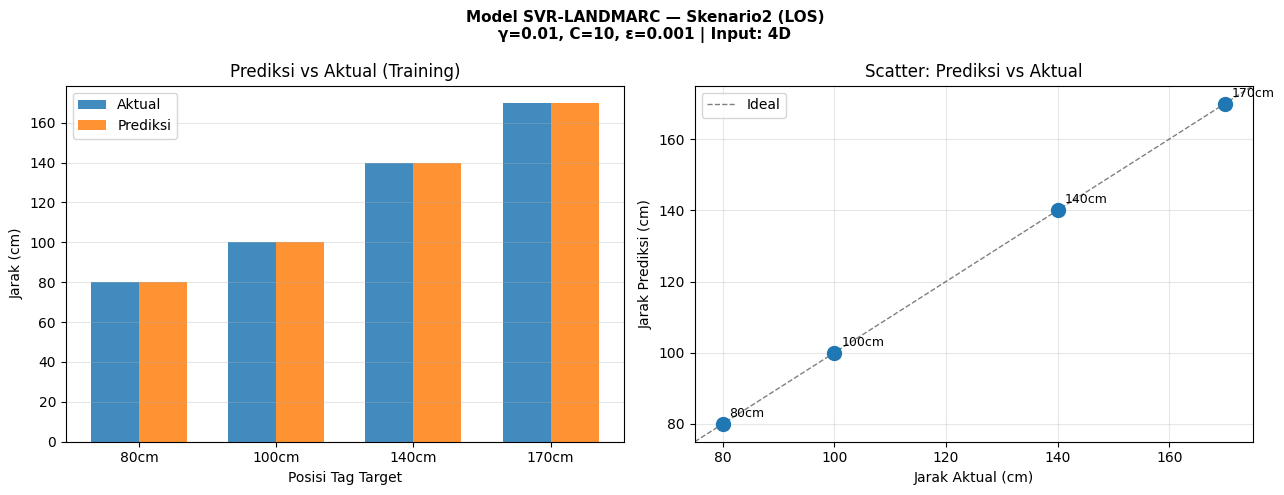

✅ Visualisasi disimpan.


In [23]:
y_act_cm = np.array([pembulatan_cm(y) for y in data_train["y"]])
y_pred_plot_cm = y_pred_cm
x_labels = [f"{pembulatan_cm(data['jarak_aktual_m'])}cm" for data in data_target]
x_pos = np.arange(len(data_target))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle(
    f"Model SVR-LANDMARC — {nama_skenario} (LOS)\n"
    f"γ={model['gamma']}, C={model['C']}, ε={model['epsilon']} | "
    f"Input: {model['X_train'].shape[1]}D",
    fontsize=11, fontweight="bold"
)

# Panel 1 — Prediksi vs Aktual
ax1 = axes[0]
width = 0.35
ax1.bar(x_pos - width / 2, y_act_cm, width, label="Aktual", alpha=0.85)
ax1.bar(x_pos + width / 2, y_pred_plot_cm, width, label="Prediksi", alpha=0.85)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(x_labels)
ax1.set_xlabel("Posisi Tag Target")
ax1.set_ylabel("Jarak (cm)")
ax1.set_title("Prediksi vs Aktual (Training)")
ax1.legend()
ax1.grid(True, alpha=0.3, axis="y")

# Panel 2 — Scatter
ax2 = axes[1]
lim = [min(y_act_cm.min(), y_pred_plot_cm.min()) - 5, max(y_act_cm.max(), y_pred_plot_cm.max()) + 5]
ax2.plot(lim, lim, "k--", lw=1, alpha=0.5, label="Ideal")
ax2.scatter(y_act_cm, y_pred_plot_cm, s=100, zorder=5)

for i, label in enumerate(x_labels):
    ax2.annotate(label, xy=(y_act_cm[i], y_pred_plot_cm[i]),
                 xytext=(5, 5), textcoords="offset points", fontsize=9)

ax2.set_xlabel("Jarak Aktual (cm)")
ax2.set_ylabel("Jarak Prediksi (cm)")
ax2.set_title("Scatter: Prediksi vs Aktual")
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.set_xlim(lim)
ax2.set_ylim(lim)

plt.tight_layout()
plt.savefig(f"model_{nama_skenario}_LOS.png", dpi=120, bbox_inches="tight")
plt.show()

print("✅ Visualisasi disimpan.")

CELL 12 — SIMPAN MODEL KE JSON DAN EXCEL

In [25]:
def simpan_model(model: dict, gs_hasil: dict, data_target: list) -> tuple:
    ts = datetime.now().strftime("%Y%m%d_%H%M%S")

    jarak_ref_m = {
        tag: info["jarak_m"]
        for tag, info in SKENARIO[model["nama_skenario"]]["referensi"].items()
    }

    model_json = {
        model["nama_skenario"]: {
            "gamma": model["gamma"],
            "C": model["C"],
            "epsilon": model["epsilon"],
            "b": model["b"],
            "alpha_diff": model["alpha_diff"].tolist(),
            "X_train": model["X_train"].tolist(),
            "y_train": model["y_train"].tolist(),
            "urutan_ref": model["urutan_ref"],
            "kondisi": model["kondisi"],
            "n_fitur": model["n_fitur"],
            "jarak_training_cm": [pembulatan_cm(data["jarak_aktual_m"]) for data in data_target],
            "jarak_ref_m": jarak_ref_m,
            "implementasi": "SVR_manual",
        }
    }

    json_file = f"model_svr_landmarc_{ts}.json"
    with open(json_file, "w") as f:
        json.dump(model_json, f, indent=2)

    print(f"✅ Model disimpan ke JSON: {json_file}")
    print(f"   Jarak referensi tersimpan: {jarak_ref_m}")

    wb = Workbook()
    wb.remove(wb.active)

    ws1 = wb.create_sheet(title=f"{model['nama_skenario']}_Parameter")
    ws1.append(["Parameter", "Nilai", "Keterangan"])
    ws1.append(["gamma (γ)", model["gamma"], "Skala kernel RBF — Persamaan 2.15"])
    ws1.append(["C", model["C"], "Konstanta regularisasi"])
    ws1.append(["epsilon (ε)", model["epsilon"], "Zona toleransi error SVR"])
    ws1.append(["bias (b)", round(model["b"], 6), "Bias global model — Persamaan 3.5"])
    ws1.append(["Jumlah data training", len(model["X_train"]), ""])
    ws1.append(["Dimensi input", model["n_fitur"], f"[{'+'.join(model['urutan_ref'])}+Target]"])
    ws1.append([])
    ws1.append(["Tag Referensi", "Jarak (m)"])

    for tag, jarak in jarak_ref_m.items():
        ws1.append([tag, jarak])

    ws1.append([])
    ws1.append(["Posisi Target (cm)", "Vektor Input", "Jarak Aktual (m)"])

    for i, data in enumerate(data_target):
        ws1.append([
            pembulatan_cm(data["jarak_aktual_m"]),
            str(np.round(model["X_train"][i], 4).tolist()),
            data["jarak_aktual_m"],
        ])

    ws2 = wb.create_sheet(title="GridSearch_Top10")
    ws2.append(["Rank", "gamma", "C", "epsilon", "MAE CV (cm)", "RMSE CV (cm)"])

    for i, hasil in enumerate(gs_hasil["hasil_grid"][:10], 1):
        ws2.append([
            i, hasil["gamma"], hasil["C"], hasil["epsilon"],
            round(hasil["mae"] * 100, 2),
            round(hasil["rmse"] * 100, 2),
        ])

    for ws in wb.worksheets:
        for col in ws.columns:
            width = max((len(str(cell.value or "")) for cell in col), default=0)
            ws.column_dimensions[col[0].column_letter].width = min(width + 4, 35)

    excel_file = f"model_svr_landmarc_{ts}.xlsx"
    wb.save(excel_file)

    print(f"✅ Model disimpan ke Excel: {excel_file}")
    return json_file, excel_file


json_file, excel_file = simpan_model(model, gs_hasil, data_target)
files.download(json_file)
files.download(excel_file)

print("\n✅ Kedua file didownload.")

✅ Model disimpan ke JSON: model_svr_landmarc_20260930_170856.json
   Jarak referensi tersimpan: {'R1': 0.5, 'R2': 1.25, 'R3': 2.0}
✅ Model disimpan ke Excel: model_svr_landmarc_20260930_170856.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ Kedua file didownload.


CELL 13 — RINGKASAN AKHIR

In [26]:
print("\n" + "=" * 60)
print(f"  RINGKASAN MODEL SVR-LANDMARC (LOS) — {nama_skenario}")
print("=" * 60)

print(f"\n  Hyperparameter : γ={model['gamma']}, C={model['C']}, ε={model['epsilon']}")
print(f"  Bias (b)       : {model['b']:.6f}")
print(f"  Input model    : vektor {model['X_train'].shape[1]}D [{'+'.join(model['urutan_ref'])}+Target]")
print(f"  MAE training   : {mae:.2f} cm")
print(f"  RMSE training  : {rmse:.2f} cm")
print(f"\n  Data training  : {len(data_target)} posisi tag target")

for data in data_target:
    vec = ", ".join(f"{value:.3f}" for value in data["vektor_input"])
    print(f"    {pembulatan_cm(data['jarak_aktual_m'])}cm → [{vec}]")

print("\n" + "=" * 60)
print("  ✅ Training selesai!")
print(f"  File: {json_file}")
print("=" * 60)


  RINGKASAN MODEL SVR-LANDMARC (LOS) — Skenario2

  Hyperparameter : γ=0.01, C=10, ε=0.001
  Bias (b)       : 1.304405
  Input model    : vektor 4D [R1+R2+R3+Target]
  MAE training   : 0.00 cm
  RMSE training  : 0.00 cm

  Data training  : 4 posisi tag target
    80cm → [-42.000, -52.000, -60.000, -46.000]
    100cm → [-42.000, -52.000, -60.000, -52.000]
    140cm → [-43.000, -50.129, -61.936, -54.000]
    170cm → [-42.000, -51.000, -61.000, -59.000]

  ✅ Training selesai!
  File: model_svr_landmarc_20260930_170856.json
